In [1]:
#exp2 TANUSHRI BHISE A28

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load dataset
df = pd.read_csv("Uber.csv")

# Remove missing values
df = df.dropna()

# Remove duplicates
df = df.drop_duplicates()

# Convert datetime
df["pickup_datetime"] = pd.to_datetime(df["pickup_datetime"])

df["year"] = df["pickup_datetime"].dt.year
df["month"] = df["pickup_datetime"].dt.month
df["day"] = df["pickup_datetime"].dt.day
df["hour"] = df["pickup_datetime"].dt.hour

# Drop unnecessary columns
df = df.drop(["key","pickup_datetime"], axis=1)

print(df.head())

   Unnamed: 0  fare_amount  pickup_longitude  pickup_latitude  \
0    24238194          7.5        -73.999817        40.738354   
1    27835199          7.7        -73.994355        40.728225   
2    44984355         12.9        -74.005043        40.740770   
3    25894730          5.3        -73.976124        40.790844   
4    17610152         16.0        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  year  month  day  \
0         -73.999512         40.723217                1  2015      5    7   
1         -73.994710         40.750325                1  2009      7   17   
2         -73.962565         40.772647                1  2009      8   24   
3         -73.965316         40.803349                3  2009      6   26   
4         -73.973082         40.761247                5  2014      8   28   

   hour  
0    19  
1    20  
2    21  
3     8  
4    17  


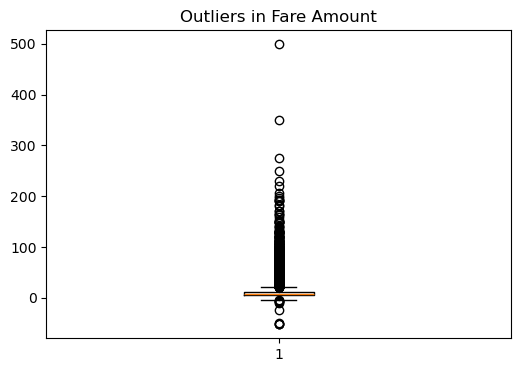

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.boxplot(df["fare_amount"])
plt.title("Outliers in Fare Amount")
plt.show()

In [3]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR

df = df[(df["fare_amount"]>=lower) & (df["fare_amount"]<=upper)]

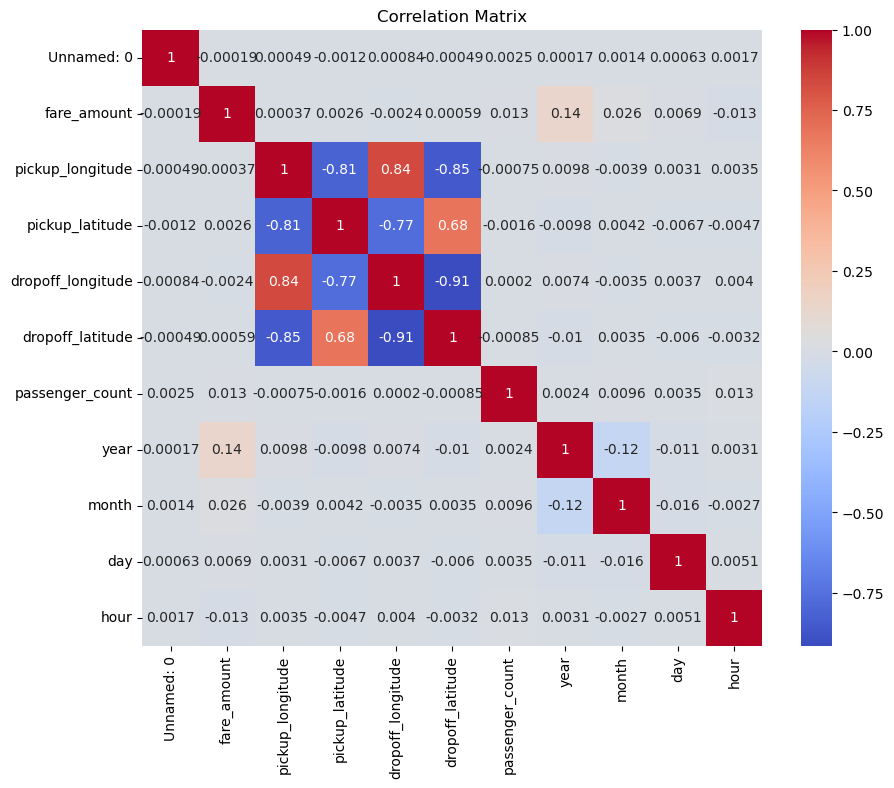

In [8]:
import seaborn as sns

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

# Standardization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42)

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)

print("R2:", r2_score(y_test,pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test,pred_lr)))
print("MAE:", mean_absolute_error(y_test,pred_lr))

R2: 0.02140425124084011
RMSE: 4.092283924509715
MAE: 3.2412916817440767


In [6]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0)

ridge.fit(X_train,y_train)

pred_ridge = ridge.predict(X_test)

print("R2:", r2_score(y_test,pred_ridge))
print("RMSE:", np.sqrt(mean_squared_error(y_test,pred_ridge)))
print("MAE:", mean_absolute_error(y_test,pred_ridge))

R2: 0.021404243821776525
RMSE: 4.092283940022205
MAE: 3.241291753653965


In [7]:
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.01)

lasso.fit(X_train,y_train)

pred_lasso = lasso.predict(X_test)

print("R2:", r2_score(y_test,pred_lasso))
print("RMSE:", np.sqrt(mean_squared_error(y_test,pred_lasso)))
print("MAE:", mean_absolute_error(y_test,pred_lasso))

R2: 0.021352779218962725
RMSE: 4.092391545740572
MAE: 3.241562823758045
